# 05 · How far is the target task? Supervised ceiling and fine-tuning

Zero-shot failure alone does not say whether FoG is hard to detect from a trunk sensor, or
whether the SisFall model learned the wrong thing. Two reference points answer that:

* **Target-trained** (from scratch on Daphnet): the in-domain ceiling for each architecture.
* **Fine-tuned** from the SisFall weights: does fall pre-training help, hurt, or do nothing?

Both are run with a full label budget (6 training patients) and a small one (2 training
patients) under 5-fold patient-grouped cross-validation. For fold k, the test patients are
`FOLDS[k]`, the validation patients (early stopping and threshold) are `FOLDS[k+1]`, and the
rest are used for training. S04 and S10 never freeze; they are paired with patients who do so
every test fold contains FoG.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score

sys.path.insert(0, str(Path.cwd().parent))
from src import config as C
from src.engine import predict_proba, train_model
from src.experiment import load_all, load_scaler
from src.metrics import binary_metrics, fbeta_threshold
from src.models import build_model
from src.plotting import save, set_style

set_style()
X_sis, meta_sis, X_dap, meta_dap = load_all()
del X_sis
tgt_scaler = load_scaler("target")
X_dom = tgt_scaler.transform(X_dap)
y = meta_dap.label.values
subj = meta_dap.subject.values
best_hp = json.load(open(C.METRICS / "best_hparams.json"))

FOLDS = [["S01", "S04"], ["S02", "S10"], ["S03", "S05"], ["S06", "S07"], ["S08", "S09"]]
assert sorted(sum(FOLDS, [])) == sorted(np.unique(subj)), np.unique(subj)
print(meta_dap.groupby("subject").label.agg(["size", "sum"]).T)

subject   S01   S02   S03   S04   S05   S06   S07  S08   S09   S10
size     1897  1413  2006  2068  2084  1985  1608  766  1735  1848
sum       102   181   288     0   475   133    82  203   270     0


In [2]:
TARGET_CFG = {"epochs": 15, "patience": 4}
FT_LR_FACTOR = 0.3   # gentler steps keep more of the pre-trained features
rows, all_preds = [], {}
csv_path = C.METRICS / "target_adaptation_per_fold.csv"
done = set()
if csv_path.exists():
    rows = pd.read_csv(csv_path).to_dict("records")
    done = {(r["arch"], r["fold"], r["condition"]) for r in rows}

for arch in C.ARCHS:
    hp = dict(best_hp[arch])
    lr = hp.pop("lr")
    src_state = torch.load(C.MODELS_DIR / arch.replace("-", "").lower() / "seed0.pt",
                           weights_only=False, map_location="cpu")["state_dict"]
    zs_model = build_model(arch, hp)
    zs_model.load_state_dict(src_state)
    for k in range(len(FOLDS)):
        test_s, val_s = FOLDS[k], FOLDS[(k + 1) % len(FOLDS)]
        train_s = [s for f in FOLDS for s in f if s not in test_s + val_s]
        # small budget: the two training patients with the most FoG windows
        fog_counts = meta_dap[meta_dap.subject.isin(train_s)].groupby("subject").label.sum()
        small_s = list(fog_counts.sort_values(ascending=False).index[:2])
        te, va = np.isin(subj, test_s), np.isin(subj, val_s)

        # zero-shot reference on the same test patients (SisFall seed-0 model)
        p_val_zs = predict_proba(zs_model, X_dom[va])
        p_te_zs = predict_proba(zs_model, X_dom[te])
        if (arch, k, "zero-shot") not in done:
            m = binary_metrics(y[te], p_te_zs, fbeta_threshold(y[va], p_val_zs) if y[va].sum() else 0.5)
            rows.append({"arch": arch, "fold": k, "condition": "zero-shot", "budget": "none", **m})

        for budget, tr_s in [("6 patients", train_s), ("2 patients", small_s)]:
            tr = np.isin(subj, tr_s)
            for init in ("scratch", "SisFall pre-trained"):
                cond = f"{init} · {budget}"
                if (arch, k, cond) in done:
                    continue
                t0 = time.time()
                model, hist, info = train_model(
                    arch, hp, X_dap[tr], y[tr], X_dom[va], y[va], tgt_scaler,
                    cfg={**TARGET_CFG, "lr": lr * (FT_LR_FACTOR if init != "scratch" else 1.0)},
                    seed=0, init_state=src_state if init != "scratch" else None, verbose=False)
                p_va = predict_proba(model, X_dom[va])
                p_te = predict_proba(model, X_dom[te])
                m = binary_metrics(y[te], p_te, fbeta_threshold(y[va], p_va))
                rows.append({"arch": arch, "fold": k, "condition": cond, "budget": budget,
                             "best_epoch": info["best_epoch"], **m})
                all_preds[(arch, k, cond)] = p_te
                print(f"{arch:12s} fold {k} {cond:34s} AUROC {m['auroc']:.3f} AUPRC {m['auprc']:.3f} "
                      f"({(time.time() - t0) / 60:.1f} min)", flush=True)
                pd.DataFrame(rows).to_csv(csv_path, index=False)
pd.DataFrame(rows).to_csv(csv_path, index=False)
res = pd.DataFrame(rows)

In [3]:
ORDER = ["zero-shot", "scratch · 2 patients", "SisFall pre-trained · 2 patients",
         "scratch · 6 patients", "SisFall pre-trained · 6 patients"]
tab = (res.groupby(["condition", "arch"])[["auroc", "auprc", "recall", "specificity", "f1"]]
       .agg(["mean", "std"]).round(3))
tab = tab.reindex(pd.MultiIndex.from_product([ORDER, C.ARCHS]))
tab.to_csv(C.METRICS / "target_adaptation_summary.csv")
tab

auroc         auprc         \
                                               mean    std   mean    std   
zero-shot                        CNN-1D       0.395  0.220  0.114  0.087   
                                 LSTM         0.549  0.235  0.123  0.116   
                                 GRU          0.641  0.199  0.155  0.130   
                                 Transformer  0.687  0.128  0.163  0.120   
scratch · 2 patients             CNN-1D       0.714  0.123  0.238  0.153   
                                 LSTM         0.351  0.256  0.104  0.072   
                                 GRU          0.548  0.255  0.195  0.161   
                                 Transformer  0.696  0.153  0.215  0.102   
SisFall pre-trained · 2 patients CNN-1D       0.617  0.144  0.161  0.081   
                                 LSTM         0.435  0.170  0.089  0.075   
                                 GRU          0.588  0.167  0.132  0.126   
                                 Transformer  0.668  0.195  0.179  0.111   
scratch · 6 patients             CNN-1D       0.786  0.147  0.387  0.216   
                                 LSTM         0.608  0.251  0.202  0.145   
                                 GRU          0.769  0.189  0.373  0.172   
                                 Transformer  0.776  0.178  0.350  0.172   
SisFall pre-trained · 6 patients CNN-1D       0.727  0.175  0.302  0.198   
                                 LSTM         0.437  0.173  0.099  0.092   
                                 GRU          0.700  0.201  0.223  0.210   
                                 Transformer  0.732  0.225  0.300  0.178   

                                             recall        specificity         \
                                               mean    std        mean    std   
zero-shot                        CNN-1D       0.753  0.422       0.223  0.427   
                                 LSTM         0.764  0.432       0.365  0.349   
                                 GRU          0.774  0.318       0.395  0.351   
                                 Transformer  0.802  0.303       0.496  0.211   
scratch · 2 patients             CNN-1D       0.523  0.297       0.707  0.281   
                                 LSTM         0.395  0.417       0.615  0.469   
                                 GRU          0.492  0.474       0.598  0.447   
                                 Transformer  0.503  0.414       0.705  0.290   
SisFall pre-trained · 2 patients CNN-1D       0.415  0.332       0.679  0.332   
                                 LSTM         0.633  0.452       0.307  0.255   
                                 GRU          0.733  0.315       0.350  0.254   
                                 Transformer  0.764  0.243       0.467  0.243   
scratch · 6 patients             CNN-1D       0.639  0.231       0.776  0.108   
                                 LSTM         0.587  0.424       0.472  0.431   
                                 GRU          0.678  0.410       0.601  0.287   
                                 Transformer  0.643  0.384       0.656  0.395   
SisFall pre-trained · 6 patients CNN-1D       0.657  0.178       0.662  0.284   
                                 LSTM         0.654  0.435       0.257  0.270   
                                 GRU          0.552  0.301       0.612  0.348   
                                 Transformer  0.627  0.376       0.524  0.331   

                                                 f1         
                                               mean    std  
zero-shot                        CNN-1D       0.120  0.119  
                                 LSTM         0.142  0.122  
                                 GRU          0.186  0.092  
                                 Transformer  0.223  0.153  
scratch · 2 patients             CNN-1D       0.212  0.100  
                                 LSTM         0.079  0.089  
                                 GRU          0.082  0.069  
                                 Transfor

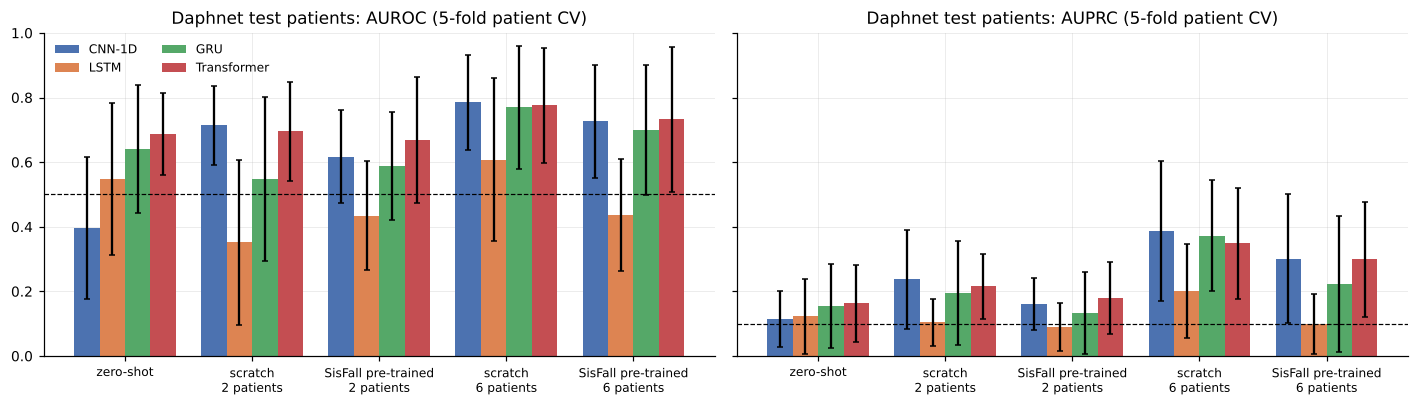

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, metric, name in [(axes[0], "auroc", "AUROC"), (axes[1], "auprc", "AUPRC")]:
    for i, arch in enumerate(C.ARCHS):
        d = res[res.arch == arch].groupby("condition")[metric]
        mu, sd = d.mean().reindex(ORDER), d.std().reindex(ORDER)
        ax.bar(np.arange(len(ORDER)) + (i - 1.5) * 0.2, mu, 0.2, yerr=sd, capsize=2,
               color=C.PALETTE[arch], label=arch)
    if metric == "auroc":
        ax.axhline(0.5, ls="--", c="k", lw=0.8)
    else:
        ax.axhline(y.mean(), ls="--", c="k", lw=0.8)
    ax.set_xticks(range(len(ORDER)), [o.replace(" · ", "\n") for o in ORDER], fontsize=8)
    ax.set_title(f"Daphnet test patients: {name} (5-fold patient CV)")
    ax.set_ylim(0, 1)
axes[0].legend(frameon=False, ncol=2, fontsize=8)
fig.tight_layout()
save(fig, "fig19_target_adaptation")

In [5]:
# paired comparison: does SisFall pre-training change AUROC, fold by fold?
from scipy.stats import wilcoxon
paired = []
for arch in C.ARCHS:
    for budget in ["2 patients", "6 patients"]:
        a = res[(res.arch == arch) & (res.condition == f"scratch · {budget}")].sort_values("fold").auroc.values
        b = res[(res.arch == arch) & (res.condition == f"SisFall pre-trained · {budget}")].sort_values("fold").auroc.values
        paired.append({"arch": arch, "budget": budget, "scratch": a.mean(), "pre-trained": b.mean(),
                       "mean diff": (b - a).mean(), "folds improved": int((b > a).sum()),
                       "wilcoxon p": wilcoxon(b, a).pvalue if np.any(a != b) else 1.0})
paired = pd.DataFrame(paired)
paired.to_csv(C.METRICS / "pretraining_effect.csv", index=False)
paired.round(4)

,arch,budget,scratch,pre-trained,mean diff,folds improved,wilcoxon p
0,CNN-1D,2 patients,0.7139,0.6167,-0.0972,1,0.3125
1,CNN-1D,6 patients,0.7857,0.7265,-0.0592,1,0.1250
2,LSTM,2 patients,0.3514,0.4346,0.0832,3,0.4375
3,LSTM,6 patients,0.6081,0.4367,-0.1714,1,0.1250
4,GRU,2 patients,0.5478,0.5879,0.0401,2,1.0000
5,GRU,6 patients,0.7694,0.6996,-0.0698,1,0.1250
6,Transformer,2 patients,0.6957,0.6677,-0.0280,2,0.6250
7,Transformer,6 patients,0.7759,0.7324,-0.0436,1,0.1250
